# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

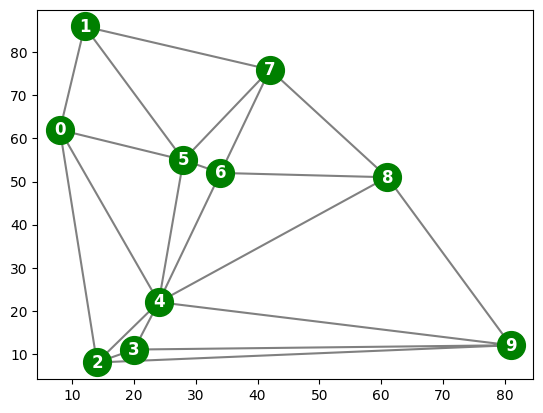

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:],
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)).

In [55]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))

neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [56]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables:
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [57]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']]))

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =",
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red',
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [58]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)

    return(True)

print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =",
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Implement Simple Backtracking Search

In [59]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)

    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =",
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [60]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0

    assignment = backtrack({}, csp)

    print(f"Checked nodes: {COUNT}")

    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT

    COUNT += 1

    if complete(assignment, csp):
        return assignment

    var = select_unassigned_var(assignment, csp)

    # TODO: implement value ordering. Use the least-constraining-value heuristic.
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val

        if VERBOSE: print(f"Checking: {assignment}")

        if consistent(assignment, csp):

            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)

        del assignment[var]

    if VERBOSE: print(f"Backtracking")
    return(None)

## Run Backtracking Search on the Random Problem

In [61]:
%time res = backtrack_search(csp)
display(res)


Checked nodes: 11
CPU times: user 304 µs, sys: 0 ns, total: 304 µs
Wall time: 311 µs


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

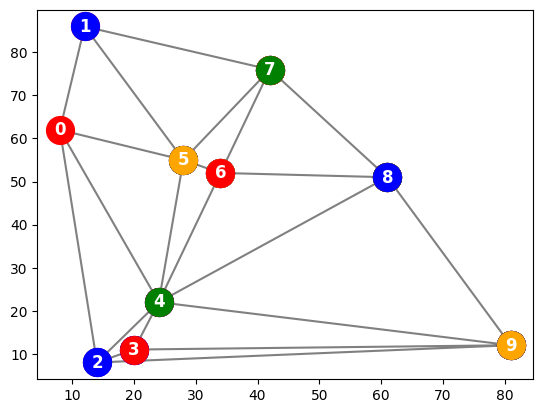

In [62]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:],
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

In [63]:
#Phép gán rỗng
print("Gán rỗng")
print("Complete:", complete({}, csp))
print("Consistent:", consistent({}, csp))
print("")

# Phép gán một phần hợp lệ
assignment = {'0': 'red', '2': 'blue'}
print("Gán assignment = {'0': 'red', '2': 'blue'}")
print("Complete:", complete(assignment, csp))
print("Consistent:", consistent(assignment, csp))
print("")

# Phép gán đầy đủ (10 đỉnh)
print("Gán assignment = {'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4':'red',\n'5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}")
assignment = {'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}
print("Complete:", complete(assignment, csp))
print("Consistent:", consistent(assignment, csp))
print("")

# Phép gán vi phạm (hai đỉnh kề 0 và 1 cùng màu)
print("Gán assignment = {'0': 'red', '1': 'red', '2': 'blue'}")
assign_inconsistent = {'0': 'red', '1': 'red', '2': 'blue'}
print("Complete:", complete(assign_inconsistent, csp))
print("Consistent:", consistent(assign_inconsistent, csp))

Gán rỗng
Complete: False
Consistent: True

Gán assignment = {'0': 'red', '2': 'blue'}
Complete: False
Consistent: True

Gán assignment = {'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4':'red',
'5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}
Complete: True
Consistent: False

Gán assignment = {'0': 'red', '1': 'red', '2': 'blue'}
Complete: False
Consistent: False


In [68]:
#Phép gán thiếu nhưng hợp lệ
assignment = {'0': 'red'}
print("Complete:", complete({}, csp))
print("Consistent:", consistent({}, csp))
print("")

#Phép gán đầy đủ nhưng vi phạm ràng buộc
assignment = {'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}
print("Complete:", complete(assignment, csp))
print("Consistent:", consistent(assignment, csp))
print("")

#Phép gán đầy đủ và hợp lệ
assignment = {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
print("Complete:", complete(assignment, csp))
print("Consistent:", consistent(assignment, csp))

Complete: False
Consistent: True

Complete: True
Consistent: False

Complete: True
Consistent: True


## Bài 3 – So sánh thứ tự chọn biến và thứ tự giá trị

Các phiên bản dưới đây chạy trên cùng một CSP: chọn biến theo thứ tự ban đầu, chọn theo MRV, và MRV kết hợp LCV. `COUNT` đếm số lần gọi đệ quy (nút tìm kiếm), còn thời gian được đo riêng. Để so sánh công bằng, không thay đổi đồ thị hoặc miền màu giữa các phiên bản.


In [64]:
import time
import pandas as pd
import copy

def legal_values(var, assignment, csp):
    """Màu hợp lệ của var theo các biến láng giềng đã được gán."""
    used = set()
    for a, b in csp["constraints"]:
        if a == var and b in assignment:
            used.add(assignment[b])
        elif b == var and a in assignment:
            used.add(assignment[a])
    return [value for value in csp["domains"][var] if value not in used]

def select_var_order(assignment, csp, strategy="original"):
    unassigned = [v for v in csp["variables"] if v not in assignment]
    if not unassigned:
        return None
    if strategy == "original":
        return unassigned[0]
    if strategy == "mrv":
        # MRV: ưu tiên biến có ít màu hợp lệ nhất; phá hòa theo thứ tự gốc.
        return min(unassigned, key=lambda v: len(legal_values(v, assignment, csp)))
    raise ValueError("strategy phải là 'original' hoặc 'mrv'")

def order_values(var, assignment, csp, strategy="original"):
    values = list(csp["domains"][var])
    if strategy == "original":
        return values
    if strategy == "lcv":
        # LCV: màu loại bỏ ít lựa chọn hợp lệ nhất khỏi các láng giềng chưa gán.
        def impact(value):
            trial = dict(assignment)
            trial[var] = value
            removed = 0
            for a, b in csp["constraints"]:
                neighbor = b if a == var else (a if b == var else None)
                if neighbor is not None and neighbor not in trial:
                    if value in legal_values(neighbor, trial, csp):
                        removed += 1
            return removed
        return sorted(values, key=impact)
    raise ValueError("strategy phải là 'original' hoặc 'lcv'")

def backtracking_variant(csp, var_strategy="original", value_strategy="original"):
    """Backtracking không Forward Checking; trả về (nghiệm, COUNT, thời gian)."""
    count = 0
    start = time.perf_counter()

    def recurse(assignment):
        nonlocal count
        count += 1
        if len(assignment) == len(csp["variables"]):
            return dict(assignment)
        var = select_var_order(assignment, csp, var_strategy)
        for value in order_values(var, assignment, csp, value_strategy):
            assignment[var] = value
            if consistent(assignment, csp):
                result = recurse(assignment)
                if result is not None:
                    return result
            del assignment[var]
        return None

    result = recurse({})
    elapsed = time.perf_counter() - start
    return result, count, elapsed

# Chạy trên đúng đồ thị CSP đang được tạo ở phần đầu notebook.
results_b3 = []
configs = [
    ("Backtracking gốc", "original", "original"),
    ("MRV", "mrv", "original"),
    ("MRV + LCV", "mrv", "lcv"),
]
for name, vs, vals in configs:
    solution, count, elapsed = backtracking_variant(csp, vs, vals)
    results_b3.append({
        "Thuật toán": name,
        "Có nghiệm": solution is not None,
        "COUNT (nút đệ quy)": count,
        "Thời gian (ms)": round(elapsed * 1000, 3),
    })
    print(name, "=>", solution)

pd.DataFrame(results_b3)


Backtracking gốc => {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
MRV => {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'red', '7': 'orange', '8': 'green'}
MRV + LCV => {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'red', '7': 'orange', '8': 'green'}


,Thuật toán,Có nghiệm,COUNT (nút đệ quy),Thời gian (ms)
0,Backtracking gốc,True,11,0.133
1,MRV,True,11,0.273
2,MRV + LCV,True,11,0.550


### Trực quan hóa nghiệm Bài 3

Chọn nghiệm của phiên bản MRV + LCV để vẽ. Nếu thuật toán không tìm thấy nghiệm, không thể tô màu theo kết quả đó.


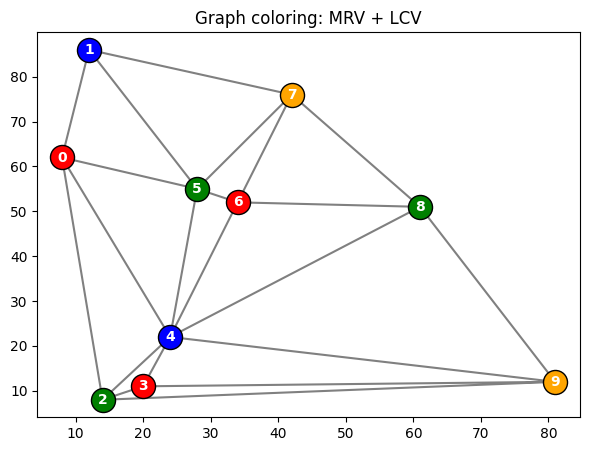

In [65]:
solution_b3, count_b3, elapsed_b3 = backtracking_variant(csp, "mrv", "lcv")
if solution_b3 is None:
    print("Không tìm thấy nghiệm cho đồ thị hiện tại.")
else:
    plt.figure(figsize=(7, 5))
    plt.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray")
    for i in range(len(points)):
        plt.scatter(points[i, 0], points[i, 1], s=300,
                    color=solution_b3[str(i)], edgecolors="black")
        plt.annotate(i, points[i, :], color="white", fontsize=10,
                     weight="bold", ha="center", va="center")
    plt.title("Graph coloring: MRV + LCV")
    plt.show()


## Bài 4 – Forward Checking và Min-Conflicts

Forward Checking lưu lại các miền màu trước khi loại màu xung đột khỏi láng giềng chưa gán; nếu một miền trở thành rỗng thì quay lui và khôi phục các miền đã thay đổi. Min-Conflicts bắt đầu từ một phép gán đầy đủ, sau đó chọn ngẫu nhiên một đỉnh đang xung đột và đổi màu để giảm số cạnh vi phạm.


In [66]:
def backtracking_forward_checking(csp, var_strategy="mrv", value_strategy="lcv"):
    """Trả về (nghiệm, COUNT, thời gian). Mỗi nhánh có bản sao miền để hoàn tác an toàn."""
    count = 0
    start = time.perf_counter()
    initial_domains = {v: list(csp["domains"][v]) for v in csp["variables"]}

    def recurse(assignment, current_domains):
        nonlocal count
        count += 1
        if len(assignment) == len(csp["variables"]):
            return dict(assignment)

        # Chọn biến dựa trên miền hiện còn sau Forward Checking.
        unassigned = [v for v in csp["variables"] if v not in assignment]
        if var_strategy == "mrv":
            var = min(unassigned, key=lambda v: len(current_domains[v]))
        else:
            var = unassigned[0]

        values = list(current_domains[var])
        if value_strategy == "lcv":
            def impact(value):
                removed = 0
                for a, b in csp["constraints"]:
                    nei = b if a == var else (a if b == var else None)
                    if nei is not None and nei not in assignment and value in current_domains[nei]:
                        removed += 1
                return removed
            values.sort(key=impact)

        for value in values:
            if any(
                (a == var and b in assignment and assignment[b] == value) or
                (b == var and a in assignment and assignment[a] == value)
                for a, b in csp["constraints"]
            ):
                continue

            new_assignment = dict(assignment)
            new_assignment[var] = value
            new_domains = {v: list(d) for v, d in current_domains.items()}
            failed = False

            for a, b in csp["constraints"]:
                nei = b if a == var else (a if b == var else None)
                if nei is not None and nei not in new_assignment:
                    new_domains[nei] = [x for x in new_domains[nei] if x != value]
                    if not new_domains[nei]:
                        failed = True
                        break

            if not failed:
                result = recurse(new_assignment, new_domains)
                if result is not None:
                    return result
        return None

    result = recurse({}, initial_domains)
    return result, count, time.perf_counter() - start


def min_conflicts(csp, max_steps=10000, seed=None):
    """Min-Conflicts; trả về (nghiệm hoặc None, số bước, thời gian)."""
    rng = np.random.default_rng(seed)
    variables = list(csp["variables"])
    domains = {v: list(csp["domains"][v]) for v in variables}
    neighbors_map = {v: set() for v in variables}
    for a, b in csp["constraints"]:
        neighbors_map[a].add(b)
        neighbors_map[b].add(a)

    start = time.perf_counter()
    assignment = {v: rng.choice(domains[v]) for v in variables}

    def conflicts_for(v, color):
        return sum(assignment[nei] == color for nei in neighbors_map[v])

    for step in range(max_steps + 1):
        conflicted = [v for v in variables if conflicts_for(v, assignment[v]) > 0]
        if not conflicted:
            return assignment, step, time.perf_counter() - start
        if step == max_steps:
            break
        var = rng.choice(conflicted)
        scores = {color: conflicts_for(var, color) for color in domains[var]}
        best_score = min(scores.values())
        best_colors = [color for color, score in scores.items() if score == best_score]
        assignment[var] = rng.choice(best_colors)

    return None, max_steps, time.perf_counter() - start


# So sánh hai thuật toán trên CSP đang có.
fc_solution, fc_count, fc_time = backtracking_forward_checking(csp)
mc_solution, mc_steps, mc_time = min_conflicts(csp, max_steps=10000, seed=123)
pd.DataFrame([
    {"Thuật toán": "Backtracking + Forward Checking", "Có nghiệm": fc_solution is not None,
     "COUNT / bước": fc_count, "Thời gian (ms)": round(fc_time*1000, 3)},
    {"Thuật toán": "Min-Conflicts", "Có nghiệm": mc_solution is not None,
     "COUNT / bước": mc_steps, "Thời gian (ms)": round(mc_time*1000, 3)},
])


,Thuật toán,Có nghiệm,COUNT / bước,Thời gian (ms)
0,Backtracking + Forward Checking,True,11,0.662
1,Min-Conflicts,True,14,0.982


## Thí nghiệm nhiều kích thước và 3/4 màu

Để so sánh các thuật toán trên nhiều đồ thị, hàm dưới đây tạo đồ thị ngẫu nhiên bằng Delaunay triangulation. Mỗi cấu hình được lặp nhiều lần với seed khác nhau. Tỷ lệ thành công của Min-Conflicts là tỷ lệ lần tìm được phép gán không xung đột trong giới hạn bước; thất bại của thuật toán heuristic không chứng minh đồ thị vô nghiệm.


In [67]:
from scipy.spatial import Delaunay

def make_random_csp(n, num_colors=3, seed=0):
    rng = np.random.default_rng(seed)
    pts = rng.random((n, 2))
    triangulation = Delaunay(pts)
    edges = set()
    for simplex in triangulation.simplices:
        for i in range(3):
            a, b = sorted((int(simplex[i]), int(simplex[(i+1) % 3])))
            edges.add((str(a), str(b)))
    variables_local = [str(i) for i in range(n)]
    colors_local = ["red", "blue", "green", "orange"][:num_colors]
    domains_local = {v: list(colors_local) for v in variables_local}
    return {"variables": variables_local, "domains": domains_local,
            "constraints": list(sorted(edges))}, pts, triangulation

def run_experiments(sizes=(8, 12, 16), color_counts=(3, 4), trials=5, max_steps=5000):
    rows = []
    for n_vertices in sizes:
        for k_colors in color_counts:
            for trial in range(trials):
                test_csp, _, _ = make_random_csp(n_vertices, k_colors,
                                                  seed=1000 + n_vertices*31 + k_colors*7 + trial)
                edge_count = len(test_csp["constraints"])

                # Backtracking + Forward Checking
                sol_fc, count_fc, time_fc = backtracking_forward_checking(test_csp)
                rows.append({
                    "n": n_vertices, "Màu": k_colors, "Lần chạy": trial + 1,
                    "Cạnh": edge_count, "Thuật toán": "Forward Checking",
                    "Thành công": sol_fc is not None, "COUNT / bước": count_fc,
                    "Thời gian (ms)": time_fc * 1000
                })

                # Min-Conflicts
                sol_mc, steps_mc, time_mc = min_conflicts(
                    test_csp, max_steps=max_steps,
                    seed=2000 + n_vertices*31 + k_colors*7 + trial)
                rows.append({
                    "n": n_vertices, "Màu": k_colors, "Lần chạy": trial + 1,
                    "Cạnh": edge_count, "Thuật toán": "Min-Conflicts",
                    "Thành công": sol_mc is not None, "COUNT / bước": steps_mc,
                    "Thời gian (ms)": time_mc * 1000
                })
    return pd.DataFrame(rows)

# Có thể tăng trials hoặc sizes nếu máy chạy ổn.
experiment_results = run_experiments(sizes=(8, 12, 16), color_counts=(3, 4),
                                     trials=5, max_steps=5000)
display(experiment_results.round({"Thời gian (ms)": 3}))

summary_results = (experiment_results.groupby(["n", "Màu", "Thuật toán"])
                   .agg(Tỷ_lệ_thành_công=("Thành công", "mean"),
                        Cạnh_trung_bình=("Cạnh", "mean"),
                        COUNT_bước_trung_bình=("COUNT / bước", "mean"),
                        Thời_gian_ms_trung_bình=("Thời gian (ms)", "mean"))
                   .reset_index())
summary_results["Tỷ_lệ_thành_công"] *= 100
display(summary_results.round(2))


,n,Màu,Lần chạy,Cạnh,Thuật toán,Thành công,COUNT / bước,Thời gian (ms)
0,8,3,1,17,Forward Checking,True,9,0.212
1,8,3,1,17,Min-Conflicts,True,5,0.829
2,8,3,2,15,Forward Checking,True,9,0.159
3,8,3,2,15,Min-Conflicts,True,11,1.213
4,8,3,3,16,Forward Checking,False,22,0.312
5,8,3,3,16,Min-Conflicts,False,5000,214.542
6,8,3,4,16,Forward Checking,False,22,0.356
7,8,3,4,16,Min-Conflicts,False,5000,214.866
8,8,3,5,15,Forward Checking,True,9,0.122
9,8,3,5,15,Min-Conflicts,True,13,0.775


,n,Màu,Thuật toán,Tỷ_lệ_thành_công,Cạnh_trung_bình,COUNT_bước_trung_bình,Thời_gian_ms_trung_bình
0,8,3,Forward Checking,60.0,15.8,14.2,0.23
1,8,3,Min-Conflicts,60.0,15.8,2005.8,86.44
2,8,4,Forward Checking,100.0,15.8,9.0,0.13
3,8,4,Min-Conflicts,100.0,15.8,5.6,0.42
4,12,3,Forward Checking,0.0,26.4,34.0,0.66
5,12,3,Min-Conflicts,0.0,26.4,5000.0,246.96
6,12,4,Forward Checking,100.0,27.2,13.0,0.30
7,12,4,Min-Conflicts,100.0,27.2,24.2,1.62
8,16,3,Forward Checking,20.0,38.4,24.6,0.65
9,16,3,Min-Conflicts,20.0,38.4,4058.6,236.41


## Gợi ý phân tích kết quả

- MRV thường giảm nhánh tìm kiếm bằng cách xử lý biến khó nhất trước; LCV ưu tiên màu gây ít hạn chế nhất cho các biến còn lại. Tuy nhiên, số nút và thời gian thực tế phụ thuộc đồ thị và thứ tự phá hòa.
- Forward Checking phát hiện nhánh thất bại sớm khi miền của một đỉnh chưa gán bị rỗng. Nó có thể kiểm tra ít nút hơn nhưng chi phí xử lý miền mỗi bước cao hơn.
- Min-Conflicts thường phù hợp cho bài toán lớn, nhưng là tìm kiếm cục bộ: kết quả phụ thuộc khởi tạo và giới hạn bước. Với 3 màu, đồ thị có thể không tô được; cần phân biệt “không tìm thấy nghiệm trong giới hạn” với “đã chứng minh vô nghiệm”.
- Báo cáo nên ghi rõ `n`, số màu, số lần thử, số cạnh trung bình, giới hạn bước và seed. Không nên kết luận một thuật toán luôn nhanh hơn chỉ từ một đồ thị hoặc một lần chạy.
